# Flow Matching: Linearity Analysis on 2-D Toy Targets

**Goal:** Train an OT-CFM model (Gaussian → configurable target) and probe how well the learned
vector field $u_t(x)$ is approximated by a global affine map $A_t x + b_t$ at each time $t$.

Set `TARGET` in the data section (`two_moons`, `gaussian`, `two_gaussians`, `checkerboard`).

**Roadmap:**
1. Train OT-CFM with a simple MLP on 2-D toy data
2. Sample via Euler ODE integration, visualise trajectories
3. Plot the learned vector field at several time slices
4. **Linearity probes**
   - Global affine fit at fixed $t$ → residual map $\|u_t(x) - (A_t x + b_t)\|$
   - Local Jacobian $J_t(x) = \partial_x u_t$ via `torch.func.jacfwd` → spatial variation of $J$
   - Sanity check: Gaussian→Gaussian should give $J$ constant everywhere

## 1 · Imports

In [1]:
import math
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch
import torch.nn as nn
from sklearn.datasets import make_moons
from tqdm.auto import tqdm

from torchcfm.conditional_flow_matching import (
    ExactOptimalTransportConditionalFlowMatcher,
    ConditionalFlowMatcher,
)

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for this notebook — no GPU detected.")

device = torch.device("cuda")

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)

print(f"device: {device}  ({torch.cuda.get_device_name(device)})")

2026-07-10 11:16:59.917463: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-07-10 11:16:59.917498: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-07-10 11:16:59.918612: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-10 11:17:00.643408: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


device: cuda  (NVIDIA RTX A5000)


In [11]:
"""
Load the JAX/Flax two-moons flow-map checkpoint and convert it to a
matching PyTorch model.

Architecture (from configs/two_moons.py + network_utils.py):
  FlowMapMLP
  - Input : [s, t, x/rescale]  →  dim 4  (2 time scalars + 2-D point)
  - phi_mlp (MLP):
      Linear(4  → 256) + GELU
      Linear(256 → 256) + GELU  (× n_hidden = 3)
      Linear(256 → 2)
  - phi = rescale * mlp(inp)
  - X(s,t,x) = x + (t-s) * phi

Key conversion detail:
  Flax Dense kernel shape : [in, out]
  PyTorch Linear weight   : [out, in]  → must transpose
"""

import sys, os
sys.path.insert(0, "/home/shervink/flow_matching/flow-maps/py")

import numpy as np
import torch
import torch.nn as nn
from flax.serialization import msgpack_restore
from common.datasets import sample_two_moons

# ── paths ────────────────────────────────────────────────────────────────────
CKPT = "/home/shervink/flow_matching/flow-maps/py/checkpoints/two_moons_paper_lsd_15.pkl"

# Must match training: adaptive gaussian_scale sets network.rescale = std(target)
RESCALE = float(np.std(sample_two_moons(500_000)))
print(f"RESCALE (from training data std): {RESCALE:.4f}")

# ── 1. load raw parameter dict ────────────────────────────────────────────────
with open(CKPT, "rb") as f:
    raw = msgpack_restore(f.read())

# The EMATrainState serialises as:
#   raw["params"]      → TrainState.params  (the variable collection)
#   raw["ema_params"]  → dict keyed by EMA factor
#
# Use the EMA-smoothed weights (0.999) for inference.
ema_key = list(raw["ema_params"].keys())[0]
print(f"EMA keys available: {list(raw['ema_params'].keys())}")
print(f"Using EMA key: {ema_key!r}   step={int(raw['step'])}")

phi = raw["ema_params"][ema_key]["params"]["flow_map"]["phi_mlp"]
print("phi_mlp Dense layers found:", sorted(phi.keys()))
for k in sorted(phi.keys()):
    print(f"  {k}: kernel {phi[k]['kernel'].shape}  bias {phi[k]['bias'].shape}")

# ── 2. define matching PyTorch model ─────────────────────────────────────────
class FlowMapMLP(nn.Module):
    """
    Replicates FlowMapMLP from network_utils.py.
    forward(s, t, x) returns X(s,t,x) = x + (t-s) * phi(s,t,x).
    s, t : scalars or (N,) tensors
    x    : (N, 2) tensor
    """
    def __init__(self, n_hidden=3, n_neurons=256, input_dim=4, output_dim=2,
                 rescale=0.5):
        super().__init__()
        self.rescale = rescale
        layers = []
        in_dim = input_dim
        # first layer
        layers += [nn.Linear(in_dim, n_neurons), nn.GELU()]
        # n_hidden hidden layers
        for _ in range(n_hidden):
            layers += [nn.Linear(n_neurons, n_neurons), nn.GELU()]
        # output layer
        layers += [nn.Linear(n_neurons, output_dim)]
        self.phi_mlp = nn.Sequential(*layers)

    def forward(self, s, t, x):
        # x : (N, 2);  s, t : () or (N,)
        if s.dim() == 0:
            s = s.expand(x.shape[0])
            t = t.expand(x.shape[0])
        st = torch.stack([s, t], dim=-1)          # (N, 2)
        inp = torch.cat([st, x / self.rescale], dim=-1)   # (N, 4)
        phi = self.rescale * self.phi_mlp(inp)     # (N, 2)
        return x + (t - s).unsqueeze(-1) * phi     # X(s,t,x)


# ── 3. copy Flax weights → PyTorch ───────────────────────────────────────────
def flax_to_pt(flax_dense, pt_linear):
    """Copy a single Flax Dense layer into a PyTorch Linear layer."""
    W = torch.from_numpy(np.array(flax_dense["kernel"]))   # [in, out]
    b = torch.from_numpy(np.array(flax_dense["bias"]))     # [out]
    pt_linear.weight.data.copy_(W.T)   # PyTorch wants [out, in]
    pt_linear.bias.data.copy_(b)

model = FlowMapMLP(n_hidden=3, n_neurons=256, input_dim=4, output_dim=2,
                   rescale=RESCALE).to(device)

# phi_mlp Sequential layout:
#   [0] Linear  [1] GELU  [2] Linear  [3] GELU  ... [2k] Linear  [2k+1] GELU  [last] Linear
# Dense_0 → layer 0, Dense_1 → layer 2, Dense_2 → layer 4, ..., Dense_4 → layer 8
dense_to_seq = {
    "Dense_0": 0,
    "Dense_1": 2,
    "Dense_2": 4,
    "Dense_3": 6,
    "Dense_4": 8,
}
for dense_name, seq_idx in dense_to_seq.items():
    flax_to_pt(phi[dense_name], model.phi_mlp[seq_idx])

print("\nWeights copied successfully.")

# ── 4. quick sanity check ─────────────────────────────────────────────────────
model.eval()
with torch.no_grad():
    x_test = torch.randn(5, 2, device=device)
    s_test = torch.zeros(5, device=device)
    t_test = torch.ones(5, device=device)
    out = model(s_test, t_test, x_test)
    print(f"Test output shape: {out.shape}  (expected (5, 2))")
    print(f"Sample output:\n{out.cpu().numpy().round(4)}")




RESCALE (from training data std): 0.7501
EMA keys available: ['0.999']
Using EMA key: '0.999'   step=15000
phi_mlp Dense layers found: ['Dense_0', 'Dense_1', 'Dense_2', 'Dense_3', 'Dense_4']
  Dense_0: kernel (4, 256)  bias (256,)
  Dense_1: kernel (256, 256)  bias (256,)
  Dense_2: kernel (256, 256)  bias (256,)
  Dense_3: kernel (256, 256)  bias (256,)
  Dense_4: kernel (256, 2)  bias (2,)

Weights copied successfully.
Test output shape: torch.Size([5, 2])  (expected (5, 2))
Sample output:
[[ 1.2153 -0.4485]
 [-0.0236  1.095 ]
 [-1.2916  0.175 ]
 [-0.3471 -0.6031]
 [-1.3276 -0.0351]]


RESCALE used: 0.7501
target std: 0.7497   base std: 0.7509
 1-step generated std: 0.7483
 5-step generated std: 0.7473
10-step generated std: 0.7491
25-step generated std: 0.7492


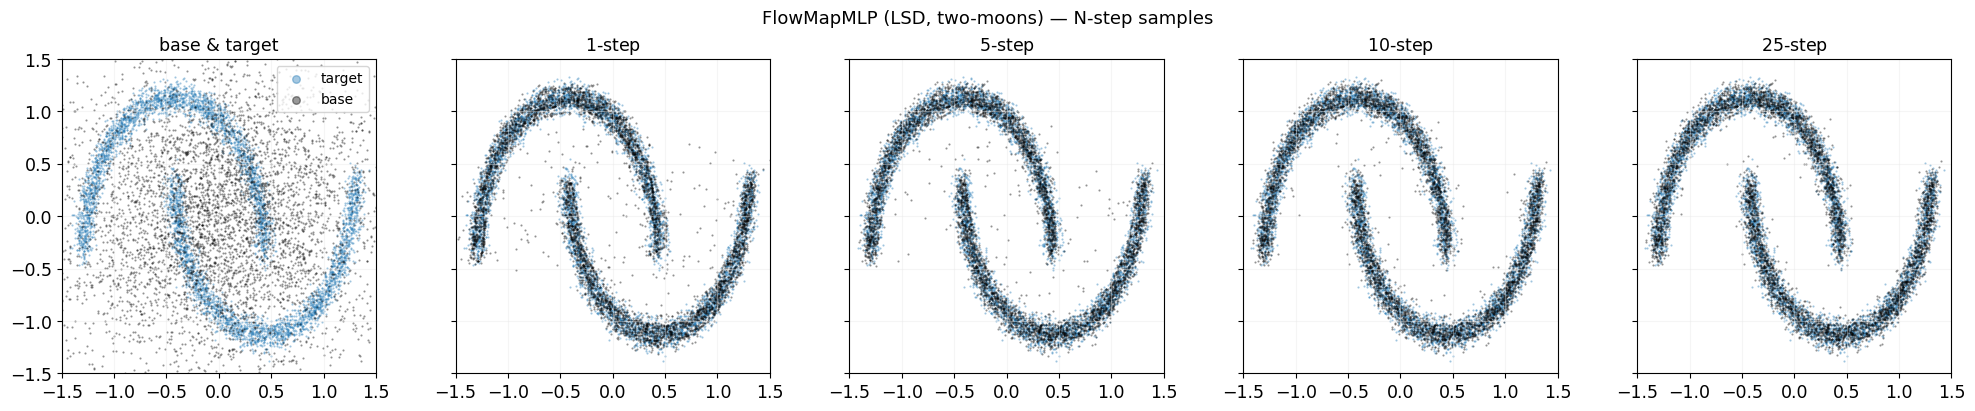

In [12]:
"""
Visualise flow-map samples at 1, 5, 10, 25 NFE (+ base/target panel).
Mirrors make_lowd_plot() in common/logging.py.

Generated points are NOT post-normalized — they are raw flow-map outputs.
Any mismatch with the target is usually from (1) wrong RESCALE at inference,
or (2) plotting target data with a different sampler/normalization than training.
"""

import sys
sys.path.insert(0, "/home/shervink/flow_matching/flow-maps/py")

import numpy as np
import matplotlib.pyplot as plt
from common.datasets import sample_two_moons

# ── helpers ───────────────────────────────────────────────────────────────────
def sample_rho0(n, rescale=RESCALE, device=device):
    """Same base distribution as training: N(0, rescale^2 I)."""
    return rescale * torch.randn(n, 2, device=device)

@torch.no_grad()
def flow_map_sample(model, x0, N):
    """Apply the flow map in N equal steps: t_0=0 → t_1 → … → t_N=1."""
    ts = torch.linspace(0.0, 1.0, N + 1, device=x0.device)
    x = x0.clone()
    for i in range(N):
        s = ts[i].expand(x.shape[0])
        t = ts[i + 1].expand(x.shape[0])
        x = model(s, t, x)
    return x

def make_target(n_plot=5_000, n_total=500_000, noise=0.05):
    """Use the exact training sampler, then subsample for plotting."""
    all_samples = sample_two_moons(n_total, noise=noise)
    idx = np.random.choice(n_total, size=n_plot, replace=False)
    return all_samples[idx]

# ── data ──────────────────────────────────────────────────────────────────────
N_PLOT  = 5_000
steps   = [1, 5, 10, 25]

x1s  = make_target(N_PLOT)                          # target (numpy)
x0s  = sample_rho0(N_PLOT)                          # noise  (torch, GPU)

print(f"RESCALE used: {RESCALE:.4f}")
print(f"target std: {x1s.std():.4f}   base std: {x0s.std().item():.4f}")

xhats = {}
model.eval()
for N in steps:
    xhats[N] = flow_map_sample(model, x0s, N).cpu().numpy()
    print(f"{N:2d}-step generated std: {xhats[N].std():.4f}")

x0s_np = x0s.cpu().numpy()

# ── plot ──────────────────────────────────────────────────────────────────────
titles = ["base & target"] + [f"${N}$-step" for N in steps]
ncols  = len(titles)
fw, fh = 4, 4
fontsize = 12.5

fig, axs = plt.subplots(1, ncols, figsize=(fw * ncols, fh),
                        sharex=True, sharey=True, constrained_layout=True)

for ax in axs:
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.grid(color="0.90", alpha=0.4)
    ax.tick_params(labelsize=fontsize)

for jj, (ax, title) in enumerate(zip(axs, titles)):
    ax.set_title(title, fontsize=fontsize)
    ax.scatter(x1s[:, 0], x1s[:, 1], s=0.3, alpha=0.4, c="C0", label="target")
    if jj == 0:
        ax.scatter(x0s_np[:, 0], x0s_np[:, 1], s=0.3, alpha=0.4,
                   c="black", label="base")
    else:
        N = steps[jj - 1]
        ax.scatter(xhats[N][:, 0], xhats[N][:, 1], s=0.3, alpha=0.4,
                   c="black", label="generated")

axs[0].legend(markerscale=10, fontsize=10, loc="upper right")
plt.suptitle("FlowMapMLP (LSD, two-moons) — N-step samples", fontsize=13)
plt.show()

## 2 · Data

Set `TARGET` to choose the target distribution $p_1$ (source is always a standard Gaussian).

In [13]:
from typing import Optional, Tuple

# ── Target selection ──────────────────────────────────────────────────────────
# Options: "two_moons" | "gaussian" | "two_gaussians" | "checkerboard"
TARGET = "two_moons"

TARGET_OPTIONS = {
    "two_moons": "Two Moons",
    "gaussian": "Single Gaussian",
    "two_gaussians": "Mixture of Two Gaussians",
    "checkerboard": "Checkerboard",
}
if TARGET not in TARGET_OPTIONS:
    raise ValueError(f"TARGET must be one of {list(TARGET_OPTIONS)}, got {TARGET!r}")
TARGET_NAME = TARGET_OPTIONS[TARGET]


def _center_scale(X: np.ndarray) -> np.ndarray:
    X = X - X.mean(0)
    return X / (X.std(0) + 1e-8)


def sample_moons(n: int, noise: float = 0.05, scale: float = 0.75) -> torch.Tensor:
    """
    Samples two interleaved half-circles (two-moons), centered and scaled by std,
    using sklearn.datasets.make_moons.
    """
    from sklearn.datasets import make_moons

    samples, _ = make_moons(n_samples=n, noise=noise, random_state=None)
    samples = samples.astype(np.float32)
    samples = _center_scale(samples)
    samples = scale * samples
    return torch.tensor(samples, dtype=torch.float32)


def sample_target_gaussian(n: int, mean: Tuple[float, float] = (2.0, 0.0), std: float = 0.5) -> torch.Tensor:
    """Single isotropic Gaussian target."""
    mu = torch.tensor(mean, dtype=torch.float32)
    return torch.randn(n, 2) * std + mu


def sample_two_gaussians(n: int, std: float = 0.35) -> torch.Tensor:
    """Balanced mixture of two isotropic Gaussians."""
    n1, n2 = n // 2, n - n // 2
    g1 = torch.randn(n1, 2) * std + torch.tensor([1.5, 1.0])
    g2 = torch.randn(n2, 2) * std + torch.tensor([-1.5, -1.0])
    return torch.cat([g1, g2], dim=0)


def sample_checkerboard(n: int) -> torch.Tensor:
    """Classic checkerboard target (cf. CFM toy examples)."""
    x1 = torch.rand(n) * 4 - 2
    x2 = torch.rand(n) - torch.randint(0, 2, (n,)).float() * 2
    x2 = x2 + (torch.rand(n) - 0.5)
    return torch.stack([x1, x2], dim=1)


def sample_target(n: int) -> torch.Tensor:
    """Sample from the configured target distribution."""
    if TARGET == "two_moons":
        return sample_moons(n)
    if TARGET == "gaussian":
        return sample_target_gaussian(n)
    if TARGET == "two_gaussians":
        return sample_two_gaussians(n)
    if TARGET == "checkerboard":
        return sample_checkerboard(n)
    raise ValueError(f"Unknown TARGET: {TARGET}")


# ── Source distribution ───────────────────────────────────────────────────────
# If True, the source Gaussian is fitted to match the mean and covariance of
# the target distribution (estimated from a large sample).
# If False, source is standard N(0, I).
MATCH_SOURCE_TO_TARGET = False

_SOURCE_MU: Optional[torch.Tensor] = None
_SOURCE_L: Optional[torch.Tensor] = None   # Cholesky factor of target covariance


def _fit_source_to_target(n_est: int = 50_000) -> None:
    """Estimate target mean + covariance and cache the Cholesky factor."""
    global _SOURCE_MU, _SOURCE_L
    X = sample_target(n_est).double()      # large sample for stable estimate
    mu = X.mean(0)
    Xc = X - mu
    cov = (Xc.T @ Xc) / (n_est - 1)
    L = torch.linalg.cholesky(cov + 1e-6 * torch.eye(2, dtype=torch.double))
    _SOURCE_MU = mu.float()
    _SOURCE_L  = L.float()


def sample_gaussian(n: int) -> torch.Tensor:
    """Sample from the source distribution (standard or target-matched Gaussian)."""
    if MATCH_SOURCE_TO_TARGET:
        if _SOURCE_MU is None:
            _fit_source_to_target()
        z = torch.randn(n, 2)
        return (z @ _SOURCE_L.T) + _SOURCE_MU
    return torch.randn(n, 2)


# Quick visualisation of source and target
_SOURCE_MU = None   # reset cache when re-running this cell
if MATCH_SOURCE_TO_TARGET:
    _fit_source_to_target()
    source_label = "Gaussian  (matched to target)"
else:
    source_label = "Standard Gaussian  $\\mathcal{N}(0, I)$"
print(f"target: {TARGET}  ({TARGET_NAME})")
print(f"source: {source_label}")
x0_vis = sample_gaussian(2000).numpy()
x1_vis = sample_target(2000).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(*x0_vis.T, s=4, alpha=0.5, c="steelblue")
axes[0].set_title(f"Source  $p_0$ : {source_label}")
axes[1].scatter(*x1_vis.T, s=4, alpha=0.5, c="tomato")
axes[1].set_title(f"Target  $p_1$ : {TARGET_NAME}")
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
plt.tight_layout()
plt.show()

TypeError: unsupported operand type(s) for |: 'torch._C._TensorMeta' and 'NoneType'

## 3 · Model

In [3]:
class VectorField(nn.Module):
    """
    MLP that approximates u_t(x).
    Input:  [x (2-D), t (1-D)]  →  3-D concatenation
    Output: 2-D vector field
    """

    def __init__(self, hidden_dim: int = 256, n_layers: int = 3):
        super().__init__()
        layers: list[nn.Module] = [nn.Linear(3, hidden_dim), nn.SiLU()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.SiLU()]
        layers.append(nn.Linear(hidden_dim, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor, t: torch.Tensor | float) -> torch.Tensor:
        """
        x : (B, 2)
        t : (B,) float tensor, or scalar broadcast
        """
        if not isinstance(t, torch.Tensor):
            t = torch.full((x.shape[0],), t, dtype=x.dtype, device=x.device)
        if t.dim() == 0:
            t = t.expand(x.shape[0])
        return self.net(torch.cat([x, t.unsqueeze(-1)], dim=-1))

    def forward_t_first(self, t: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
        """Signature compatible with torchdiffeq.odeint (t scalar, x batched)."""
        return self.forward(x, t)


model = VectorField(hidden_dim=256, n_layers=3).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params:,}")
print(device)

Parameters: 133,122
cuda


## 4 · Training

Set `FM_METHOD` to `"ot_cfm"` (OT-coupled pairs) or `"cfm"` (independent pairs). Both use `sigma=0.0` (deterministic rectified-flow path).

In [4]:
# ── Hyper-parameters ──────────────────────────────────────────────────────────
N_ITER      = 10000
BATCH_SIZE  = 256
LR          = 1e-3
LOG_EVERY   = 500

# "ot_cfm" → ExactOptimalTransportConditionalFlowMatcher  (minibatch OT coupling)
# "cfm"    → ConditionalFlowMatcher                       (independent pairs)
FM_METHOD = "ot_cfm"
FM_SIGMA  = 0.0

FM_CLASSES = {
    "ot_cfm": ExactOptimalTransportConditionalFlowMatcher,
    "cfm": ConditionalFlowMatcher,
}
if FM_METHOD not in FM_CLASSES:
    raise ValueError(f"FM_METHOD must be one of {list(FM_CLASSES)}, got {FM_METHOD!r}")

FM = FM_CLASSES[FM_METHOD](sigma=FM_SIGMA)
print(f"flow matcher: {FM_METHOD}  ({FM.__class__.__name__}, sigma={FM_SIGMA})")

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_ITER, eta_min=1e-5)

# sanity check: model and optimizer state live on GPU
assert next(model.parameters()).device.type == "cuda", "model is not on CUDA"
print(f"training on: {next(model.parameters()).device}  |  target: {TARGET_NAME}")

# ── Training loop ─────────────────────────────────────────────────────────────
losses: list[float] = []

model.train()
pbar = tqdm(range(N_ITER), desc=FM_METHOD, unit="step")
for i in pbar:
    x0 = sample_gaussian(BATCH_SIZE).to(device, non_blocking=True)
    x1 = sample_target(BATCH_SIZE).to(device, non_blocking=True)

    # torchcfm OT coupling runs on CPU; move outputs back to GPU
    t, xt, ut = FM.sample_location_and_conditional_flow(x0, x1)
    t, xt, ut = t.to(device), xt.to(device), ut.to(device)

    vt = model(xt, t)
    loss = torch.mean((vt - ut) ** 2)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    scheduler.step()

    if i % LOG_EVERY == 0:
        losses.append(loss.item())

    pbar.set_postfix(
        loss=f"{loss.item():.5f}",
        lr=f"{scheduler.get_last_lr()[0]:.2e}",
        refresh=False,
    )

pbar.close()
print("Training complete.")

flow matcher: ot_cfm  (ExactOptimalTransportConditionalFlowMatcher, sigma=0.0)
training on: cuda:0  |  target: Two Moons


ot_cfm:   0%|          | 0/10000 [00:00<?, ?step/s]

Training complete.


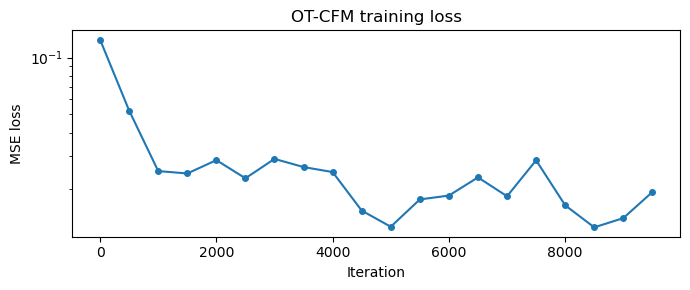

In [5]:
plt.figure(figsize=(7, 3))
plt.plot(np.arange(len(losses)) * LOG_EVERY, losses, marker="o", markersize=4)
plt.xlabel("Iteration"); plt.ylabel("MSE loss")
plt.title("OT-CFM training loss")
plt.yscale("log")
plt.tight_layout()
plt.show()

NameError: name 'ax3' is not defined

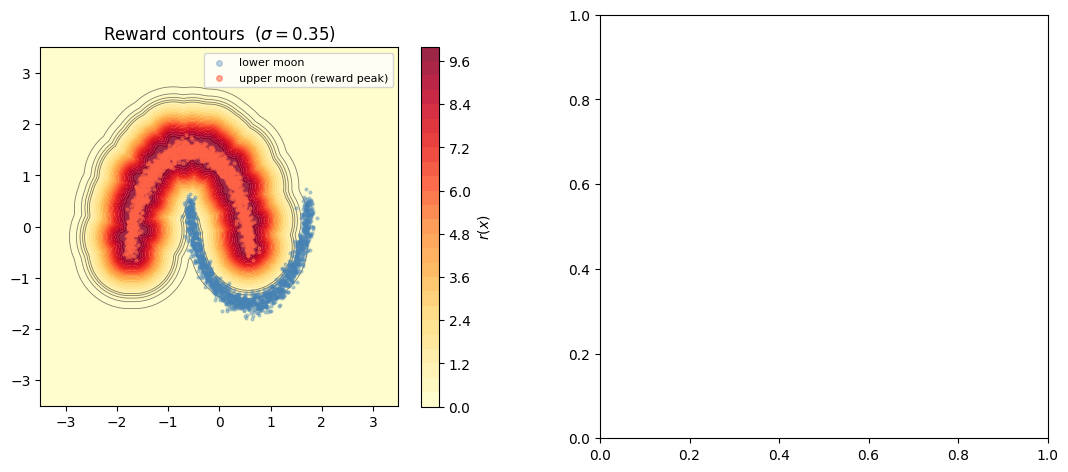

In [14]:
# ── Reward: large on the upper moon, small elsewhere ─────────────────────────
# Uses an RBF envelope over reference points on sklearn's upper moon (label 0).
# Differentiable w.r.t. x → can be passed directly to the MPC terminal reward r(x).

REWARD_SIGMA = 0.35   # width of the bump (in data coordinates after centering/scaling)
N_REF        = 400    # reference points subsampled from the upper moon

# Build reference cloud on the upper moon (same preprocessing as sample_moons).
X_moons, moon_labels = make_moons(n_samples=5000, noise=0.05, random_state=0)
X_moons = _center_scale(X_moons)
upper_mask = moon_labels == 0          # sklearn: label 0 = upper arc (higher y)
upper_pts  = torch.tensor(X_moons[upper_mask], dtype=torch.float32)
perm = torch.randperm(upper_pts.shape[0])[:N_REF]
UPPER_MOON_REF = upper_pts[perm]       # (N_REF, 2) — kept on CPU; moves with x in r()


def upper_moon_reward(x: torch.Tensor) -> torch.Tensor:
    """
    Terminal reward r(x): peaks at 1 on the upper moon, decays to ~0 elsewhere.

    r(x) = exp( - min_{p in upper_moon_ref} ||x - p||^2 / (2 σ^2) )

    Args:
        x: (B, 2) positions
    Returns:
        (B,) reward values in [0, 1]
    """
    ref = UPPER_MOON_REF.to(x.device, x.dtype)
    d2 = ((x[:, None, :] - ref[None, :, :]) ** 2).sum(dim=-1)   # (B, N_REF)
    return 10*torch.exp(-d2.min(dim=1).values / (2.0 * REWARD_SIGMA ** 2))


# Alias for MPC usage:  receding_horizon_flow_control(..., r=upper_moon_reward, ...)
# r = upper_moon_reward

# Terminal reward: prefer samples with large second coordinate.
def r(x):
    return 5.0 * x[:, 1]

# ── Contour visualisation ─────────────────────────────────────────────────────
EXTENT = 3.5
GRID   = 200
xs = np.linspace(-EXTENT, EXTENT, GRID)
ys = np.linspace(-EXTENT, EXTENT, GRID)
XX, YY = np.meshgrid(xs, ys, indexing="xy")
grid = torch.tensor(np.stack([XX.ravel(), YY.ravel()], axis=1), dtype=torch.float32)
R_grid = upper_moon_reward(grid).numpy().reshape(GRID, GRID)

# Full two-moons scatter for context (upper vs lower coloured differently).
X_vis, y_vis = make_moons(n_samples=3000, noise=0.05, random_state=1)
X_vis = _center_scale(X_vis)
upper_vis = y_vis == 0
lower_vis = y_vis == 1

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"wspace": 0.25})

# Left: filled contours + moon scatter
ax = axes[0]
cf = ax.contourf(XX, YY, R_grid, levels=30, cmap="YlOrRd", alpha=0.85)
fig.colorbar(cf, ax=ax, shrink=0.85, label="$r(x)$")
ax.contour(XX, YY, R_grid, levels=[0.1, 0.3, 0.5, 0.7, 0.9],
           colors="k", linewidths=0.6, alpha=0.5)
ax.scatter(X_vis[lower_vis, 0], X_vis[lower_vis, 1],
           s=4, alpha=0.35, c="steelblue", label="lower moon", zorder=3)
ax.scatter(X_vis[upper_vis, 0], X_vis[upper_vis, 1],
           s=4, alpha=0.55, c="tomato", label="upper moon (reward peak)", zorder=4)
ax.set_xlim(-EXTENT, EXTENT); ax.set_ylim(-EXTENT, EXTENT)
ax.set_aspect("equal")
ax.set_title(f"Reward contours  ($\\sigma={REWARD_SIGMA}$)")
ax.legend(loc="upper right", fontsize=8, markerscale=2)

# Right: 3-D surface view of the same reward landscape
ax3.plot_surface(XX, YY, R_grid, cmap="YlOrRd", alpha=0.9,
                 linewidth=0, antialiased=True)
ax3.set_xlabel("$x_1$"); ax3.set_ylabel("$x_2$"); ax3.set_zlabel("$r(x)$")
ax3.set_title("Reward surface")
ax3.view_init(elev=35, azim=-60)

plt.suptitle("Upper-Moon Reward  (large on top arc, small elsewhere)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print(f"reward at upper-moon mean : {upper_moon_reward(upper_pts.mean(0, keepdim=True)).item():.4f}")
# print(f"reward at lower-moon mean : {upper_moon_reward(torch.tensor(X_moons[~upper_mask].mean(0))).item():.4f}")
print(f"reward at origin          : {upper_moon_reward(torch.zeros(1, 2)).item():.4f}")

In [ ]:
"""
Receding-Horizon Path-Space Control for Flow Matching
=====================================================

Implements the softened path-space MPC variant:

    min_{x_{1:H}}  sum_{l=0}^{H-1} (1 / (2*lambda*dt)) * || x_{l+1} - x_l - dt * v_theta(t_{j+l}, x_l) ||^2
                   - r(x_H) + (mu/2) * || h(x_H) ||^2
    s.t. x_0 = x_cur

At each outer step j, the horizon trajectory is warm-started with the
uncontrolled flow, optimized with gradient descent (L-BFGS by default),
and only the first residual control u_j* is applied.

You must supply:
    v_theta(t, x) -> velocity, shape (B, D)   (your pretrained flow-matching field)
    r(x)          -> terminal reward, shape (B,)  (differentiable)
    h(x)          -> terminal constraint residual, shape (B, C) (optional; differentiable)

Everything is batched: x has shape (B, D).
"""

import torch
from typing import Callable, Optional


@torch.no_grad()
def _rollout_uncontrolled(
    v_theta: Callable[[torch.Tensor, torch.Tensor], torch.Tensor],
    x0: torch.Tensor,
    t0_idx: int,
    H: int,
    dt: float,
    t_grid: torch.Tensor,
) -> torch.Tensor:
    """Warm start: roll the uncontrolled flow forward H steps.

    Returns x_bar of shape (H, B, D) — the states x_1, ..., x_H
    (x_0 is the fixed current state and is not included).
    """
    xs = []
    x = x0
    for ell in range(H):
        t = t_grid[t0_idx + ell]
        x = x + dt * v_theta(t, x)
        xs.append(x)
    return torch.stack(xs, dim=0)


def _horizon_objective(
    x_traj: torch.Tensor,           # (H, B, D), the decision variables x_1..x_H
    x_cur: torch.Tensor,            # (B, D), fixed
    v_theta: Callable,
    r: Callable,
    h: Optional[Callable],
    t0_idx: int,
    dt: float,
    lam: float,
    mu: float,
    t_grid: torch.Tensor,
) -> torch.Tensor:
    """Softened path-space objective, summed over the batch (scalar)."""
    H = x_traj.shape[0]
    # Full state sequence x_0..x_H with x_0 fixed at the current state.
    x_full = torch.cat([x_cur.unsqueeze(0), x_traj], dim=0)  # (H+1, B, D)

    # Control-energy term: sum_l ||x_{l+1} - x_l - dt * v(t_{j+l}, x_l)||^2 / (2*lam*dt)
    energy = x_full.new_zeros(x_full.shape[1])  # (B,)
    for ell in range(H):
        t = t_grid[t0_idx + ell]
        resid = x_full[ell + 1] - x_full[ell] - dt * v_theta(t, x_full[ell])  # (B, D)
        energy = energy + resid.pow(2).sum(dim=-1) / (2.0 * lam * dt)

    x_H = x_full[-1]
    obj = energy - r(x_H)  # (B,)

    if h is not None and mu > 0.0:
        hx = h(x_H)
        if hx.dim() == 1:
            hx = hx.unsqueeze(-1)
        obj = obj + 0.5 * mu * hx.pow(2).sum(dim=-1)

    return obj.sum()


def solve_horizon_problem(
    x_cur: torch.Tensor,
    v_theta: Callable,
    r: Callable,
    h: Optional[Callable],
    t0_idx: int,
    H: int,
    dt: float,
    lam: float,
    mu: float,
    t_grid: torch.Tensor,
    optimizer: str = "lbfgs",
    n_iters: int = 50,
    lr: float = 0.1,
) -> torch.Tensor:
    """Solve the finite-horizon path-space problem; return optimal x_1 (B, D)."""
    # Warm start with the uncontrolled flow trajectory.
    x_init = _rollout_uncontrolled(v_theta, x_cur, t0_idx, H, dt, t_grid)
    x_traj = x_init.clone().requires_grad_(True)
    x_cur_fixed = x_cur.detach()

    if optimizer.lower() == "lbfgs":
        opt = torch.optim.LBFGS(
            [x_traj], lr=lr, max_iter=n_iters,
            tolerance_grad=1e-8, tolerance_change=1e-10,
            line_search_fn="strong_wolfe",
        )

        def closure():
            opt.zero_grad()
            loss = _horizon_objective(
                x_traj, x_cur_fixed, v_theta, r, h,
                t0_idx, dt, lam, mu, t_grid,
            )
            loss.backward()
            return loss

        opt.step(closure)
    else:  # adam
        opt = torch.optim.Adam([x_traj], lr=lr)
        for _ in range(n_iters):
            opt.zero_grad()
            loss = _horizon_objective(
                x_traj, x_cur_fixed, v_theta, r, h,
                t0_idx, dt, lam, mu, t_grid,
            )
            loss.backward()
            opt.step()

    return x_traj[0].detach()  # x_1^*


@torch.no_grad()
def _apply_first_step(x_j, x1_star):
    # x_{j+1} = x_j + dt*(v + u*) = x_j + (x1* - x_j) = x1*  (by construction)
    return x1_star


def receding_horizon_flow_control(
    v_theta: Callable[[torch.Tensor, torch.Tensor], torch.Tensor],
    r: Callable[[torch.Tensor], torch.Tensor],
    x0: torch.Tensor,
    N: int = 100,
    H: int = 10,
    lam: float = 0.1,
    mu: float = 0.0,
    h: Optional[Callable[[torch.Tensor], torch.Tensor]] = None,
    optimizer: str = "lbfgs",
    n_iters: int = 50,
    lr: float = 0.1,
    verbose: bool = False,
    device: Optional[torch.device] = None,
):
    """
    Algorithm 1: Receding-Horizon Path-Space Control for Flow Matching.

    Args:
        v_theta: learned flow-matching vector field, v_theta(t, x) -> (B, D).
                 t is a scalar tensor; broadcast it inside your model as needed.
        r:       terminal reward, r(x) -> (B,), differentiable.
        x0:      initial samples from p_0, shape (B, D).
        N:       number of discretization steps (dt = 1/N).
        H:       horizon length (clipped near the end of the interval).
        lam:     control weight lambda > 0 (smaller => stay closer to the flow).
        mu:      terminal-constraint penalty (0 disables the h-term).
        h:       terminal constraint residual h(x) -> (B, C), differentiable.
        optimizer: "lbfgs" or "adam" for the inner path-space solve.
        n_iters: inner-solver iterations per MPC step.
        lr:      inner-solver learning rate.
        device:  torch device for all tensors (defaults to x0.device).

    Returns:
        x_N:      final controlled samples, shape (B, D).
        traj:     full controlled trajectory, shape (N+1, B, D).
        controls: applied residual controls u_j*, shape (N, B, D).
    """
    if device is None:
        device = x0.device
    x0 = x0.to(device)
    dt = 1.0 / N
    t_grid = torch.linspace(0.0, 1.0, N + 1, device=device, dtype=x0.dtype)

    x = x0.detach().clone()
    traj = [x.clone()]
    controls = []

    for j in range(N):
        H_j = min(H, N - j)  # shrink the horizon so we never step past t=1

        x1_star = solve_horizon_problem(
            x, v_theta, r, h, t0_idx=j, H=H_j, dt=dt,
            lam=lam, mu=mu, t_grid=t_grid,
            optimizer=optimizer, n_iters=n_iters, lr=lr,
        )

        # Recover the first residual control:
        # u_j* = (x_1* - x_j)/dt - v_theta(t_j, x_j)
        with torch.no_grad():
            v_j = v_theta(t_grid[j], x)
            u_star = (x1_star - x) / dt - v_j
            # Apply the first controlled step (equals x1_star exactly).
            x = x + dt * (v_j + u_star)

        traj.append(x.clone())
        controls.append(u_star.clone())

        if verbose:
            print(f"step {j+1:4d}/{N}  |u*| mean = {u_star.norm(dim=-1).mean():.4e}")

    return x, torch.stack(traj, dim=0), torch.stack(controls, dim=0)


# ----------------------------------------------------------------------------
# Example usage with a toy flow field (replace with your pretrained v_theta).
# ----------------------------------------------------------------------------

torch.manual_seed(0)
B, D = 64, 2
N_demo = 20

# v_theta expects signature (t, x) -> (B, D); VectorField.forward is (x, t).
v_theta = model.forward_t_first
mpc_device = next(model.parameters()).device



# Optional terminal constraint: pin the first coordinate to 3, h(x)=x_0-3.
def h(x):
    return x[:, 0:1] - 3.0

x0 = torch.randn(B, D, device=mpc_device)

# Uncontrolled rollout for comparison (same initial batch, no MPC).
dt_demo = 1.0 / N_demo
t_grid_demo = torch.linspace(0.0, 1.0, N_demo + 1, device=mpc_device, dtype=x0.dtype)
with torch.no_grad():
    x_unc = x0.clone()
    traj_unc_list = [x_unc.clone()]
    for j in range(N_demo):
        x_unc = x_unc + dt_demo * v_theta(t_grid_demo[j], x_unc)
        traj_unc_list.append(x_unc.clone())
traj_unc = torch.stack(traj_unc_list, dim=0)  # (N+1, B, D)

# xN, traj, controls = receding_horizon_flow_control(
#     v_theta, r, x0,
#     N=N_demo, H=10, lam=0.5, mu=10.0, h=h,
#     optimizer="lbfgs", n_iters=30, lr=0.5,
#     verbose=True, device=mpc_device,
# )

xN, traj, controls = receding_horizon_flow_control(
    v_theta, r, x0,
    N=N_demo, H=5, lam=0.5, mu=10.0,
    optimizer="lbfgs", n_iters=30, lr=0.5,
    verbose=True, device=mpc_device,
)

print("\nfinal mean (controlled):  ", xN.mean(dim=0).tolist())
print("final mean (uncontrolled):", x_unc.mean(dim=0).tolist())

step    1/20  |u*| mean = 2.4657e+00
step    2/20  |u*| mean = 2.4396e+00
step    3/20  |u*| mean = 2.4148e+00
step    4/20  |u*| mean = 2.3885e+00
step    5/20  |u*| mean = 2.3571e+00
step    6/20  |u*| mean = 2.3169e+00
step    7/20  |u*| mean = 2.2652e+00
step    8/20  |u*| mean = 2.2038e+00
step    9/20  |u*| mean = 2.1384e+00
step   10/20  |u*| mean = 2.0711e+00
step   11/20  |u*| mean = 1.9994e+00
step   12/20  |u*| mean = 1.9242e+00
step   13/20  |u*| mean = 1.8444e+00
step   14/20  |u*| mean = 1.7602e+00
step   15/20  |u*| mean = 1.6698e+00
step   16/20  |u*| mean = 1.5710e+00
step   17/20  |u*| mean = 1.6967e+00
step   18/20  |u*| mean = 1.8750e+00
step   19/20  |u*| mean = 2.1325e+00
step   20/20  |u*| mean = 2.4979e+00

final mean (controlled):   [-0.12214849889278412, 1.6900873184204102]
final mean (uncontrolled): [-0.029205895960330963, -0.09197258204221725]


/tmp/ipykernel_3198395/271778091.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


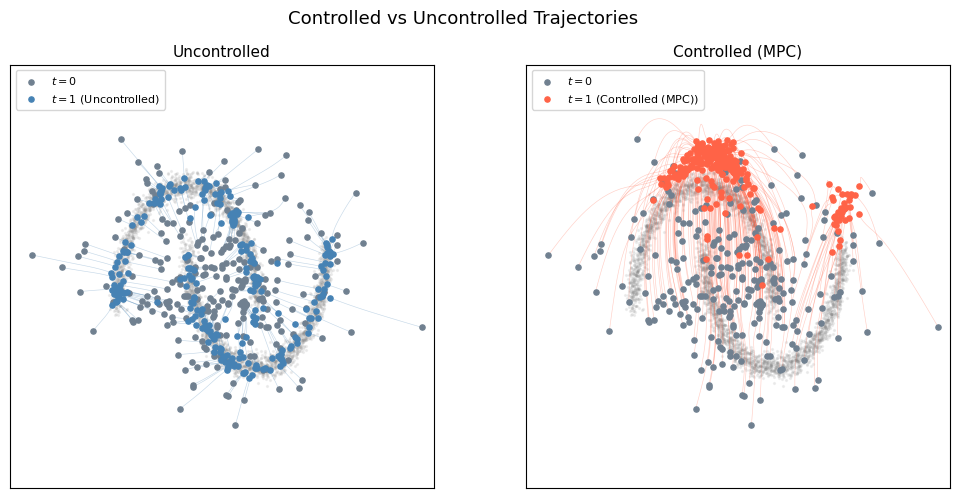

/tmp/ipykernel_3198395/271778091.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


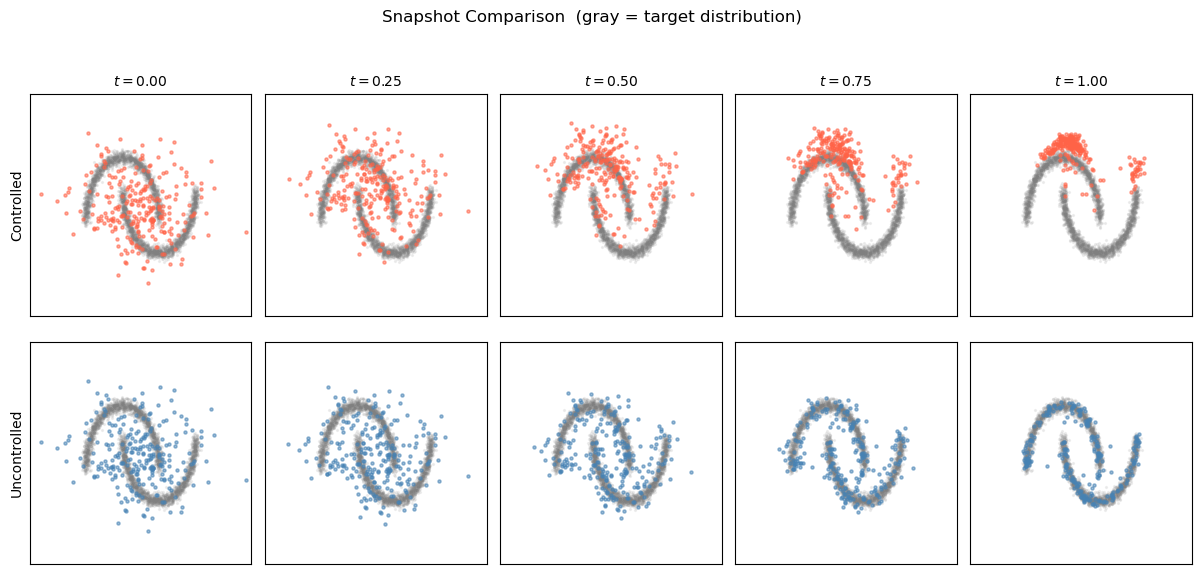

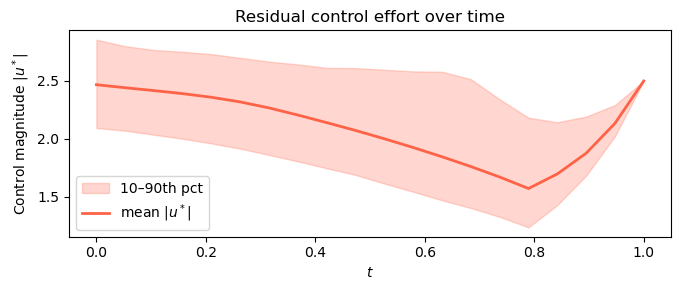

In [32]:
# ── MPC trajectory visualisation ─────────────────────────────────────────────
# Requires: xN, traj (controlled, (N+1, B, D)), x_unc (uncontrolled, (B, D))
# and x0 from the MPC cell above.
# Set these to tune the display.
VIZ_N_PARTICLES = 256          # how many individual trajectories to draw
VIZ_SHOW_SNAPS  = True        # also show per-timestep scatter snapshots
VIZ_SNAP_TIMES  = [0.0, 0.25, 0.5, 0.75, 1.0]
VIZ_LIM         = 3.5         # axis limits

traj_cpu     = traj.cpu().numpy()                # (N+1, B, D)  controlled
traj_unc_cpu = traj_unc.cpu().numpy()            # (N+1, B, D)  uncontrolled
x0_cpu       = x0.cpu().numpy()                 # (B, D)
xN_cpu       = xN.cpu().numpy()                 # (B, D)
x_unc_cpu    = x_unc.detach().cpu().numpy()      # (B, D)
bg_pts   = sample_target(4000).numpy()  # faint target reference

rng_viz  = np.random.default_rng(42)
idx_show = rng_viz.choice(traj_cpu.shape[1], size=min(VIZ_N_PARTICLES, traj_cpu.shape[1]), replace=False)

# ── Figure 1: trajectory spaghetti (controlled) ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True,
                         gridspec_kw={"wspace": 0.05})

for ax, traj_data, pts_end, label, color in [
    (axes[0], traj_unc_cpu, x_unc_cpu, "Uncontrolled", "steelblue"),
    (axes[1], traj_cpu,     xN_cpu,    "Controlled (MPC)", "tomato"),
]:
    ax.scatter(bg_pts[:, 0], bg_pts[:, 1], s=2, alpha=0.10, c="gray", zorder=0)

    for i in idx_show:
        ax.plot(traj_data[:, i, 0], traj_data[:, i, 1],
                lw=0.45, alpha=0.30, color=color)

    ax.scatter(x0_cpu[idx_show, 0], x0_cpu[idx_show, 1],
               s=14, c="slategray", zorder=5, label="$t=0$")
    ax.scatter(pts_end[idx_show, 0], pts_end[idx_show, 1],
               s=14, c=color, zorder=6, label=f"$t=1$ ({label})")

    ax.set_xlim(-VIZ_LIM, VIZ_LIM); ax.set_ylim(-VIZ_LIM, VIZ_LIM)
    ax.set_aspect("equal")
    ax.set_title(label, fontsize=11)
    ax.legend(fontsize=8, loc="upper left")
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle("Controlled vs Uncontrolled Trajectories", fontsize=13)
plt.tight_layout()
plt.show()

# ── Figure 2: side-by-side snapshot grid ─────────────────────────────────────
if VIZ_SHOW_SNAPS:
    T_steps = traj_cpu.shape[0] - 1
    snap_idx = [round(t * T_steps) for t in VIZ_SNAP_TIMES]

    ncols = len(VIZ_SNAP_TIMES)
    fig, axes = plt.subplots(2, ncols, figsize=(3.0 * ncols, 6.2),
                             gridspec_kw={"hspace": 0.08, "wspace": 0.06})

    for row, (row_label, color) in enumerate([("Controlled", "tomato"),
                                               ("Uncontrolled", "steelblue")]):
        for col, (sidx, t_val) in enumerate(zip(snap_idx, VIZ_SNAP_TIMES)):
            ax = axes[row, col]
            ax.scatter(bg_pts[:, 0], bg_pts[:, 1], s=2, alpha=0.10, c="gray", zorder=0)
            if row == 0:
                pts = traj_cpu[sidx]
            else:
                pts = traj_unc_cpu[sidx]
            ax.scatter(pts[:, 0], pts[:, 1], s=5, alpha=0.55, color=color)
            if row == 0:
                ax.set_title(f"$t = {t_val:.2f}$", fontsize=10)
            ax.set_aspect("equal")
            ax.set_xlim(-VIZ_LIM, VIZ_LIM); ax.set_ylim(-VIZ_LIM, VIZ_LIM)
            ax.set_xticks([]); ax.set_yticks([])
        axes[row, 0].set_ylabel(row_label, fontsize=10)

    fig.suptitle("Snapshot Comparison  (gray = target distribution)", fontsize=12, y=1.01)
    plt.tight_layout()
    plt.show()

# ── Figure 3: control magnitude over time ─────────────────────────────────────
controls_cpu = controls.cpu().numpy()   # (N, B, D)
u_mag = np.linalg.norm(controls_cpu, axis=-1)  # (N, B)
t_axis = np.linspace(0, 1, u_mag.shape[0])

fig, ax = plt.subplots(figsize=(7, 3))
ax.fill_between(t_axis,
                np.percentile(u_mag, 10, axis=1),
                np.percentile(u_mag, 90, axis=1),
                alpha=0.25, color="tomato", label="10–90th pct")
ax.plot(t_axis, u_mag.mean(axis=1), color="tomato", lw=2, label="mean $|u^*|$")
ax.set_xlabel("$t$")
ax.set_ylabel("Control magnitude $|u^*|$")
ax.set_title("Residual control effort over time")
ax.legend()
plt.tight_layout()
plt.show()

## 5 · Sampling via Euler ODE Integration

Integrate $\dot{x} = u_{\theta,t}(x)$ from $t=0$ to $t=1$ with a simple fixed-step Euler solver.
Drop-in replacement: use `torchdiffeq.odeint` with `method="dopri5"` for higher accuracy.

In [22]:
@torch.no_grad()
def euler_sample(
    model: VectorField,
    n: int = 2000,
    n_steps: int = 100,
    return_traj: bool = False,
    device: torch.device = device,
) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
    """Euler integration of the learned ODE from t=0 to t=1."""
    model.eval()
    x = torch.randn(n, 2, device=device)
    dt = 1.0 / n_steps
    ts = torch.linspace(0.0, 1.0 - dt, n_steps, device=device)

    # print(ts)

    traj = [x.cpu()] if return_traj else None

    u = torch.tensor([100.0, 0], device=device)

    for t_val in ts:
        v = model(x, t_val.expand(n))

        # if t_val == 0.5:
        #     x = x + dt * v + u * dt
        # else:
        x = x + dt * v
        if return_traj:
            traj.append(x.cpu())

    model.train()
    if return_traj:
        return x.cpu(), torch.stack(traj)   # (n_steps+1, n, 2)
    return x.cpu()


samples, trajectory = euler_sample(model, n=2000, n_steps=100, return_traj=True)
print(f"Generated samples: {samples.shape}  |  Trajectory: {trajectory.shape}")

Generated samples: torch.Size([2000, 2])  |  Trajectory: torch.Size([101, 2000, 2])


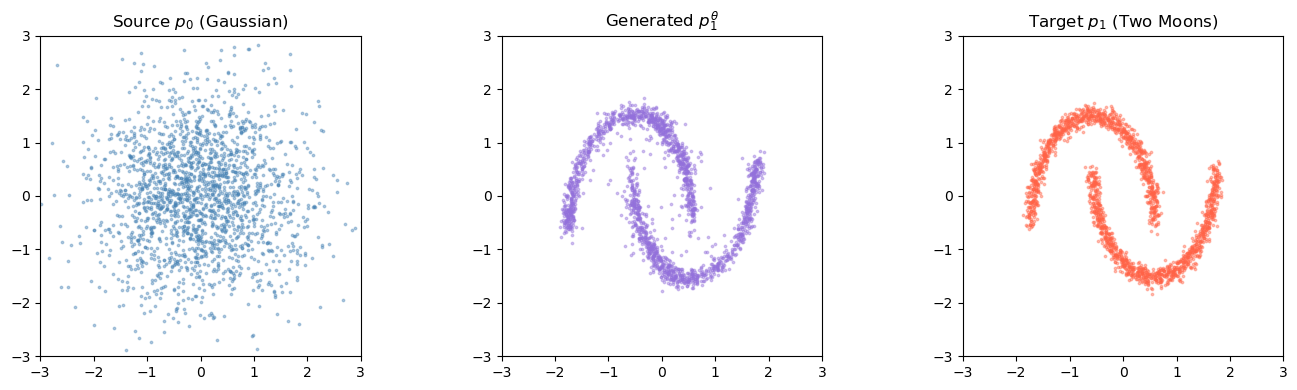

In [23]:
# ── Generated samples vs target ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

x1_ref = sample_target(2000).numpy()

axes[0].scatter(*x0_vis.T, s=3, alpha=0.4, c="steelblue")
axes[0].set_title("Source $p_0$ (Gaussian)")

axes[1].scatter(*samples.numpy().T, s=3, alpha=0.4, c="mediumpurple")
axes[1].set_title("Generated $p_1^{\\theta}$")

axes[2].scatter(*x1_ref.T, s=3, alpha=0.4, c="tomato")
axes[2].set_title(f"Target $p_1$ ({TARGET_NAME})")

lim = 3.0
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)

plt.tight_layout()
plt.show()

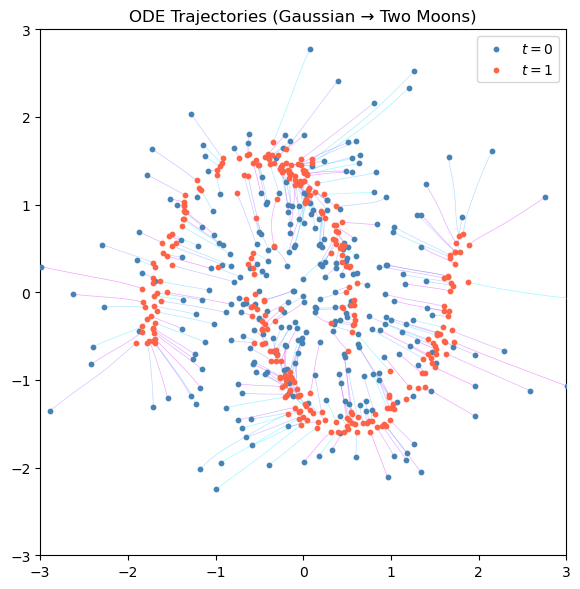

In [24]:
# ── Trajectory plot: show a subset of particles moving from 0→1 ───────────────
n_show = 300
idx = np.random.choice(2000, n_show, replace=False)
traj_sub = trajectory[:, idx, :].numpy()   # (T, n_show, 2)
T = traj_sub.shape[0]

fig, ax = plt.subplots(figsize=(6, 6))
cmap = plt.get_cmap("cool")

for i in range(n_show):
    color = cmap(i / n_show)
    ax.plot(traj_sub[:, i, 0], traj_sub[:, i, 1],
            lw=0.5, alpha=0.4, color=color)

# start & end points
ax.scatter(*traj_sub[0].T, s=10, c="steelblue", zorder=5, label="$t=0$")
ax.scatter(*traj_sub[-1].T, s=10, c="tomato", zorder=5, label="$t=1$")
ax.set_aspect("equal")
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_title(f"ODE Trajectories (Gaussian → {TARGET_NAME})")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ── Snapshot plots: distribution at fixed time steps ──────────────────────────
# Uses the full trajectory tensor (T+1, n, 2) from euler_sample above.
SNAP_TIMES = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

T_steps = trajectory.shape[0] - 1          # number of Euler steps (= n_steps)
snap_indices = [round(t * T_steps) for t in SNAP_TIMES]

ncols = len(SNAP_TIMES)
fig, axes = plt.subplots(1, ncols, figsize=(3.2 * ncols, 3.4),
                         gridspec_kw={"wspace": 0.08})

for ax, step_idx, t_val in zip(axes, snap_indices, SNAP_TIMES):
    pts = trajectory[step_idx].numpy()      # (n, 2)
    ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.45,
               c=[t_val] * len(pts), cmap="cool", vmin=0, vmax=1)
    ax.set_title(f"$t = {t_val:.1f}$", fontsize=10)
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([])

axes[0].set_ylabel("$x_2$")
fig.suptitle(f"Particle Distribution  (Gaussian → {TARGET_NAME})", fontsize=12, y=1.02)

# shared colorbar indicating time
sm = plt.cm.ScalarMappable(cmap="cool", norm=plt.Normalize(0, 1))
sm.set_array([])
fig.colorbar(sm, ax=axes, shrink=0.85, label="$t$", pad=0.02)
plt.show()

In [ ]:
# ── Localised probe: track a tight cluster from a chosen starting point ────────
# Set PROBE_MEANS to a list of (x, y) starting centres.
# Each cluster is a small-variance Gaussian; all are pushed through the ODE.
# Use None to place a cluster at a random point inside [-PROBE_RANGE, PROBE_RANGE]².

PROBE_MEANS  = None          # None → random; or e.g. [(-1.0, 0.5), (1.0, -0.5)]
N_PROBE_CLUSTERS = 4         # number of clusters (used only when PROBE_MEANS is None)
PROBE_N      = 300           # particles per cluster
PROBE_STD    = 0.08          # initial spread (small → tight cluster)
PROBE_RANGE  = 1.8           # half-range for random placement

rng = np.random.default_rng()
if PROBE_MEANS is None:
    centres = rng.uniform(-PROBE_RANGE, PROBE_RANGE, size=(N_PROBE_CLUSTERS, 2))
else:
    centres = np.array(PROBE_MEANS, dtype=np.float32)

n_clusters = len(centres)
cluster_colors = plt.cm.tab10(np.linspace(0, 0.9, n_clusters))

# faint target distribution in the background (two moons when TARGET="two_moons")
bg_pts = sample_target(4000).numpy()

# ── Run ODE for every cluster ──────────────────────────────────────────────────
@torch.no_grad()
def probe_trajectory(model: VectorField, mean: np.ndarray,
                     n: int = PROBE_N, std: float = PROBE_STD,
                     n_steps: int = 100) -> np.ndarray:
    """Integrate cluster from t=0→1; returns (n_steps+1, n, 2) numpy array."""
    x = torch.randn(n, 2) * std + torch.tensor(mean, dtype=torch.float32)
    traj = [x.clone()]
    dt = 1.0 / n_steps
    for k in range(n_steps):
        t_val = k * dt
        t_batch = torch.full((n,), t_val)
        vf = model(x.to(device), t_batch.to(device)).cpu()
        x = x + vf * dt
        traj.append(x.clone())
    return torch.stack(traj, dim=0).numpy()   # (n_steps+1, n, 2)

probe_trajs = [probe_trajectory(model, c) for c in centres]

# ── Figure 1: trajectory spaghetti ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
for traj, color, centre in zip(probe_trajs, cluster_colors, centres):
    for i in range(PROBE_N):
        ax.plot(traj[:, i, 0], traj[:, i, 1],
                lw=0.4, alpha=0.25, color=color)
    # mark start and end centroids
    ax.scatter(*traj[0].mean(0),  s=80, color=color, marker="o",
               edgecolors="black", lw=0.8, zorder=6)
    ax.scatter(*traj[-1].mean(0), s=80, color=color, marker="*",
               edgecolors="black", lw=0.8, zorder=6,
               label=f"start ({centre[0]:+.2f}, {centre[1]:+.2f})")

ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_aspect("equal")
ax.legend(fontsize=7, loc="upper left")
ax.set_title(f"Cluster trajectories  (Gaussian → {TARGET_NAME})\n"
             f"○ = start  ★ = end   std$_0$ = {PROBE_STD}")
plt.tight_layout()
plt.show()

# ── Figure 2: snapshot grid — where does each cluster end up at each t? ───────
PROBE_SNAPS = [0.0, 0.25, 0.5, 0.75, 1.0]
n_steps_traj = probe_trajs[0].shape[0] - 1
snap_idx = [round(t * n_steps_traj) for t in PROBE_SNAPS]

fig, axes = plt.subplots(1, len(PROBE_SNAPS),
                         figsize=(3.0 * len(PROBE_SNAPS), 3.2),
                         gridspec_kw={"wspace": 0.06})

for ax, sidx, t_val in zip(axes, snap_idx, PROBE_SNAPS):
    ax.scatter(bg_pts[:, 0], bg_pts[:, 1], s=2, alpha=0.12, c="tomato", zorder=0)
    for traj, color in zip(probe_trajs, cluster_colors):
        pts = traj[sidx]
        ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.55, color=color)
    ax.set_title(f"$t = {t_val:.2f}$", fontsize=10)
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle(f"Cluster evolution snapshots  (std$_0$ = {PROBE_STD})", fontsize=11, y=1.02)
plt.show()

## 6 · Vector Field at Fixed Time Slices

In [ ]:
@torch.no_grad()
def eval_vf_on_grid(
    model: VectorField,
    t_val: float,
    grid_size: int = 25,
    extent: float = 2.5,
    device: torch.device = device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Returns (X, Y, U, V) meshgrid arrays for a quiver plot."""
    model.eval()
    xs = torch.linspace(-extent, extent, grid_size)
    ys = torch.linspace(-extent, extent, grid_size)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    grid = torch.stack([XX.flatten(), YY.flatten()], dim=1).to(device)
    t_batch = torch.full((grid.shape[0],), t_val, device=device)
    uv = model(grid, t_batch).cpu().numpy()
    model.train()
    X = XX.numpy(); Y = YY.numpy()
    U = uv[:, 0].reshape(grid_size, grid_size)
    V = uv[:, 1].reshape(grid_size, grid_size)
    return X, Y, U, V


t_slices = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(1, len(t_slices), figsize=(16, 3.5))

# Colour arrows by magnitude for legibility
for ax, t_val in zip(axes, t_slices):
    X, Y, U, V = eval_vf_on_grid(model, t_val, grid_size=20)
    mag = np.sqrt(U**2 + V**2)
    ax.quiver(X, Y, U / (mag + 1e-8), V / (mag + 1e-8),
              mag, cmap="plasma", scale=25, width=0.004)
    ax.set_title(f"$u_{{\\theta}}(x,\\, t={t_val:.2f})$", fontsize=11)
    ax.set_aspect("equal")
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Learned vector field $u_{\\theta}(x, t)$ at fixed $t$ slices", y=1.02)
plt.tight_layout()
plt.show()

## 7 · Linearity Analysis

### 7.1 · Global Affine Fit at Fixed $t$

At each time $t$ we solve
$$
\min_{A_t, b_t} \sum_{x} \| u_\theta(x, t) - (A_t x + b_t) \|^2
$$
via least-squares, then colour the plane by the residual norm $\| u_\theta(x,t) - (A_t x + b_t)\|$.

In [ ]:
@torch.no_grad()
def global_affine_residuals(
    model: VectorField,
    t_val: float,
    grid_size: int = 50,
    extent: float = 2.5,
    device: torch.device = device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Returns (X, Y, residual_norm, U, V, fitted_U, fitted_V, A_t, b_t).
    Fits global least-squares affine map u ≈ A_t x + b_t at fixed t.
    """
    model.eval()
    xs = torch.linspace(-extent, extent, grid_size)
    ys = torch.linspace(-extent, extent, grid_size)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    grid = torch.stack([XX.flatten(), YY.flatten()], dim=1)   # (N, 2)
    N = grid.shape[0]

    t_batch = torch.full((N,), t_val)
    uv = model(grid.to(device), t_batch.to(device)).cpu()     # (N, 2)

    # Build design matrix [x, y, 1] for least-squares
    ones = torch.ones(N, 1)
    Phi = torch.cat([grid, ones], dim=1)   # (N, 3)

    # Solve Phi @ W = uv  →  W = (Phi^T Phi)^{-1} Phi^T uv
    W, _, _, _ = torch.linalg.lstsq(Phi, uv)   # (3, 2)
    uv_affine = (Phi @ W)                       # (N, 2)

    residual = (uv - uv_affine).norm(dim=1).numpy()

    X = XX.numpy(); Y = YY.numpy()
    R = residual.reshape(grid_size, grid_size)
    U = uv[:, 0].numpy().reshape(grid_size, grid_size)
    V = uv[:, 1].numpy().reshape(grid_size, grid_size)
    Ua = uv_affine[:, 0].numpy().reshape(grid_size, grid_size)
    Va = uv_affine[:, 1].numpy().reshape(grid_size, grid_size)
    A_t = W[:2, :].T.numpy()   # (2, 2)
    b_t = W[2, :].numpy()      # (2,)
    model.train()
    return X, Y, R, U, V, Ua, Va, A_t, b_t


t_slices = [0.0, 0.25, 0.5, 0.75, 1.0]
HEATMAP_GRID = 50
QUIVER_GRID = 20

print("Global affine fit  u_θ(x, t) ≈ A_t x + b_t")
print("─" * 50)
for t_val in t_slices:
    *_, A_t, b_t = global_affine_residuals(model, t_val, grid_size=HEATMAP_GRID)
    print(f"\nt = {t_val:.2f}")
    print("A_t =")
    print(np.array2string(A_t, precision=4, suppress_small=True))
    print(f"b_t = {np.array2string(b_t, precision=4, suppress_small=True)}")

from matplotlib.colors import Normalize

fig, axes = plt.subplots(2, len(t_slices), figsize=(18, 7),
                         gridspec_kw={"hspace": 0.35})

# precompute quiver fields + shared magnitude limits for colorbars
quiver_cache = {}
for t_val in t_slices:
    heat = global_affine_residuals(model, t_val, grid_size=HEATMAP_GRID)
    quiv = global_affine_residuals(model, t_val, grid_size=QUIVER_GRID)
    quiver_cache[t_val] = {"heat": heat, "quiv": quiv}

u_mag_max = max(
    np.sqrt(d["quiv"][3] ** 2 + d["quiv"][4] ** 2).max()
    for d in quiver_cache.values()
)
a_mag_max = max(
    np.sqrt(d["quiv"][5] ** 2 + d["quiv"][6] ** 2).max()
    for d in quiver_cache.values()
)
norm_u = Normalize(vmin=0, vmax=u_mag_max)
norm_a = Normalize(vmin=0, vmax=a_mag_max)

for col, t_val in enumerate(t_slices):
    X, Y, R, _, _, _, _, A_t, b_t = quiver_cache[t_val]["heat"]
    Xq, Yq, _, U, V, Ua, Va, _, _ = quiver_cache[t_val]["quiv"]

    # ── top row: residual heatmap ─────────────────────────────────────────────
    ax_top = axes[0, col]
    im = ax_top.pcolormesh(X, Y, R, cmap="inferno", shading="auto")
    fig.colorbar(im, ax=ax_top, shrink=0.8)
    ax_top.set_title(f"$t = {t_val:.2f}$ | residual $\\|u_\\theta - A_t x - b_t\\|$")
    ax_top.set_aspect("equal")
    ax_top.set_xticks([]); ax_top.set_yticks([])

    # ── bottom row: actual vs affine quiver (same grid for both fields) ─────────
    ax_bot = axes[1, col]
    mag = np.sqrt(U**2 + V**2) + 1e-8
    mag_a = np.sqrt(Ua**2 + Va**2) + 1e-8
    q_u = ax_bot.quiver(Xq, Yq, U / mag, V / mag, mag,
                        cmap="plasma", norm=norm_u,
                        scale=22, width=0.004, alpha=0.85, label="$u_\\theta$")
    ax_bot.quiver(Xq, Yq, Ua / mag_a, Va / mag_a, color="steelblue",
                  scale=22, width=0.004, alpha=0.7, label="$A_t x+b_t$")
    fig.colorbar(q_u, ax=ax_bot, shrink=0.72, pad=0.04, label=r"$|u_\theta|$")
    if col == 0:
        ax_bot.legend(loc="upper left", fontsize=8)
    ax_bot.set_aspect("equal")
    ax_bot.set_xticks([]); ax_bot.set_yticks([])

axes[0, 0].set_ylabel("Residual $\\|u_\\theta - Ax - b\\|$")
axes[1, 0].set_ylabel("Actual (red) vs Affine (blue)")
plt.suptitle("Global Affine Fit Residuals at Fixed $t$ Slices", fontsize=13, y=1.01)
plt.show()

# ── separate quiver maps: actual u_θ vs global affine fit ─────────────────────
fig, axes = plt.subplots(2, len(t_slices), figsize=(18, 7),
                         gridspec_kw={"hspace": 0.35})

for col, t_val in enumerate(t_slices):
    Xq, Yq, _, U, V, Ua, Va, _, _ = quiver_cache[t_val]["quiv"]
    mag = np.sqrt(U**2 + V**2) + 1e-8
    mag_a = np.sqrt(Ua**2 + Va**2) + 1e-8

    ax_u = axes[0, col]
    q_u = ax_u.quiver(Xq, Yq, U / mag, V / mag, mag,
                      cmap="plasma", norm=norm_u, scale=25, width=0.004)
    fig.colorbar(q_u, ax=ax_u, shrink=0.72, pad=0.04, label=r"$|u_\theta|$")
    ax_u.set_title(f"$u_\\theta(x, t={t_val:.2f})$")
    ax_u.set_aspect("equal")
    ax_u.set_xlim(-2.5, 2.5); ax_u.set_ylim(-2.5, 2.5)
    ax_u.set_xticks([]); ax_u.set_yticks([])

    ax_a = axes[1, col]
    q_a = ax_a.quiver(Xq, Yq, Ua / mag_a, Va / mag_a, mag_a,
                      cmap="plasma", norm=norm_a, scale=25, width=0.004)
    fig.colorbar(q_a, ax=ax_a, shrink=0.72, pad=0.04, label=r"$|A_t x + b_t|$")
    ax_a.set_title(f"$A_t x + b_t$  ($t={t_val:.2f}$)")
    ax_a.set_aspect("equal")
    ax_a.set_xlim(-2.5, 2.5); ax_a.set_ylim(-2.5, 2.5)
    ax_a.set_xticks([]); ax_a.set_yticks([])

axes[0, 0].set_ylabel("Learned field $u_\\theta$")
axes[1, 0].set_ylabel("Global affine fit")
plt.suptitle("Actual vs Affine Vector Fields (separate views)", fontsize=13, y=1.01)
plt.show()

### 7.2 · Piecewise-Interval Affine Fit

Fit a **single** affine map $A x + b$ over each user-defined time interval $[t_a, t_b]$,
pooling all grid points across $N_t$ uniformly-sampled $t$ values in that interval.
This answers: *"what is the best constant linear approximation of the flow over this time window?"*

Edit `INTERVALS` below to choose the partitioning.

In [ ]:
# ── User-defined time intervals ───────────────────────────────────────────────
# Each entry is (t_start, t_end).  Intervals may overlap or leave gaps.
INTERVALS = [
    (0.0, 0.3),
    (0.3, 0.7),
    (0.7, 1.0),
]


@torch.no_grad()
def fit_interval_affine(
    model: VectorField,
    t_start: float,
    t_end: float,
    grid_size: int = 30,
    n_t_samples: int = 10,
    extent: float = 2.5,
    device: torch.device = device,
) -> dict:
    """
    Fit a single affine map  u_θ(x, t) ≈ A x + b  for t ∈ [t_start, t_end].

    Evaluates the model on `n_t_samples` uniformly-spaced t values, each over
    a `grid_size × grid_size` spatial grid, then solves one global LSQ problem
    over all (x, t) samples jointly.

    Returns dict with keys: A (2×2), b (2,), r2 (scalar), residuals (N,).
    """
    model.eval()
    xs = torch.linspace(-extent, extent, grid_size)
    ys = torch.linspace(-extent, extent, grid_size)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    grid = torch.stack([XX.flatten(), YY.flatten()], dim=1)  # (G, 2)
    G = grid.shape[0]

    t_vals = torch.linspace(t_start, t_end, n_t_samples)

    all_x, all_u = [], []
    for t_val in t_vals:
        t_batch = torch.full((G,), float(t_val))
        uv = model(grid.to(device), t_batch.to(device)).cpu()
        all_x.append(grid)
        all_u.append(uv)

    X_all = torch.cat(all_x, dim=0)  # (G*n_t, 2)
    U_all = torch.cat(all_u, dim=0)  # (G*n_t, 2)
    N = X_all.shape[0]

    ones = torch.ones(N, 1)
    Phi = torch.cat([X_all, ones], dim=1)           # (N, 3)
    W, _, _, _ = torch.linalg.lstsq(Phi, U_all)    # (3, 2)
    U_pred = Phi @ W

    residuals = (U_all - U_pred).norm(dim=1).numpy()
    ss_res = float(((U_all - U_pred) ** 2).sum())
    ss_tot = float(((U_all - U_all.mean(0)) ** 2).sum())
    r2 = 1.0 - ss_res / (ss_tot + 1e-10)

    A = W[:2, :].T.numpy()  # (2, 2)
    b = W[2, :].numpy()     # (2,)
    model.train()
    return {"A": A, "b": b, "r2": r2, "residuals": residuals}


# ── Print fitted A and b for each interval ────────────────────────────────────
print("Piecewise-interval affine fit  u_θ(x, t) ≈ A x + b")
print("=" * 54)
interval_results = {}
for t_start, t_end in INTERVALS:
    res = fit_interval_affine(model, t_start, t_end)
    interval_results[(t_start, t_end)] = res
    label = f"t ∈ [{t_start:.2f}, {t_end:.2f}]"
    print(f"\n{label}  (R² = {res['r2']:.4f})")
    print("A =")
    print(np.array2string(res["A"], precision=4, suppress_small=True))
    print(f"b = {np.array2string(res['b'], precision=4, suppress_small=True)}")

# ── Bar chart: R² per interval ────────────────────────────────────────────────
labels = [f"[{a:.2f}, {b:.2f}]" for a, b in INTERVALS]
r2s = [interval_results[iv]["r2"] for iv in INTERVALS]

fig, ax = plt.subplots(figsize=(max(5, len(INTERVALS) * 1.6), 3.5))
bars = ax.bar(labels, r2s, color="steelblue", edgecolor="white", width=0.5)
ax.axhline(1.0, ls="--", c="gray", lw=1, label="Perfect linearity")
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set_ylim(-0.05, 1.15)
ax.set_xlabel("Time interval")
ax.set_ylabel("$R^2$ (interval affine fit)")
ax.set_title("How linear is $u_\\theta$ within each time window?")
ax.legend()
plt.tight_layout()
plt.show()

# ── Residual distribution per interval (box plot) ─────────────────────────────
fig, ax = plt.subplots(figsize=(max(5, len(INTERVALS) * 1.6), 3.5))
ax.boxplot(
    [interval_results[iv]["residuals"] for iv in INTERVALS],
    labels=labels,
    patch_artist=True,
    boxprops=dict(facecolor="steelblue", alpha=0.6),
    medianprops=dict(color="white", lw=2),
)
ax.set_xlabel("Time interval")
ax.set_ylabel("Residual $\\|u_\\theta - Ax - b\\|$")
ax.set_title("Residual distribution per interval")
plt.tight_layout()
plt.show()

### 7.2 · $R^2$ of Global Affine Fit vs. $t$

Fraction of variance explained by the best affine map. For a Gaussian→Gaussian flow this should be 1.0 everywhere; for two moons it will dip.

In [ ]:
@torch.no_grad()
def affine_r2(model: VectorField, t_val: float,
              grid_size: int = 60, extent: float = 2.5,
              device: torch.device = device) -> float:
    """Coefficient of determination (R²) for global affine fit at fixed t."""
    model.eval()
    xs = torch.linspace(-extent, extent, grid_size)
    ys = torch.linspace(-extent, extent, grid_size)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    grid = torch.stack([XX.flatten(), YY.flatten()], dim=1)
    N = grid.shape[0]

    t_batch = torch.full((N,), t_val)
    uv = model(grid.to(device), t_batch.to(device)).cpu()

    ones = torch.ones(N, 1)
    Phi = torch.cat([grid, ones], dim=1)
    W, _, _, _ = torch.linalg.lstsq(Phi, uv)
    uv_pred = Phi @ W

    ss_res = ((uv - uv_pred) ** 2).sum().item()
    ss_tot = ((uv - uv.mean(0)) ** 2).sum().item()
    model.train()
    return 1.0 - ss_res / (ss_tot + 1e-10)


t_grid = np.linspace(0.0, 1.0, 25)
r2_vals = [affine_r2(model, float(t)) for t in t_grid]

plt.figure(figsize=(7, 3.5))
plt.plot(t_grid, r2_vals, marker="o", markersize=5, color="steelblue", lw=2)
plt.axhline(1.0, ls="--", c="gray", lw=1, label="Perfect linearity ($R^2=1$)")
plt.xlabel("$t$")
plt.ylabel("$R^2$ (global affine fit)")
plt.title("How linear is $u_\\theta(\\cdot, t)$?")
plt.ylim(-0.05, 1.1)
plt.legend()
plt.tight_layout()
plt.show()

print("R² values:", {f"{t:.2f}": f"{r:.4f}" for t, r in zip(t_grid[::4], r2_vals[::4])})

### 7.3 · Local Jacobian $J_t(x) = \partial_x u_\theta(x, t)$ via `torch.func.jacfwd`

If $u_t$ were globally affine, $J_t(x)$ would be **constant** in $x$.
Spatial variation of $\|J_t(x)\|_F$ directly measures nonlinearity.

In [ ]:
from torch.func import jacfwd, vmap


def make_single_input_fn(model: VectorField, t_val: float, device: torch.device):
    """Return a function x (2,) → u (2,) with t baked in, for use with jacfwd."""
    def fn(x: torch.Tensor) -> torch.Tensor:
        return model(x.unsqueeze(0), torch.tensor([t_val], device=device)).squeeze(0)
    return fn


@torch.no_grad()
def jacobian_frob_on_grid(
    model: VectorField,
    t_val: float,
    grid_size: int = 30,
    extent: float = 2.5,
    device: torch.device = device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Returns (X, Y, ||J||_F) on a grid.
    Uses vmap + jacfwd for efficient batched Jacobian computation.
    """
    model.eval()
    xs = torch.linspace(-extent, extent, grid_size)
    ys = torch.linspace(-extent, extent, grid_size)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    grid = torch.stack([XX.flatten(), YY.flatten()], dim=1).to(device)  # (N, 2)

    t_tensor = torch.full((1,), t_val, device=device)

    def single_jac(x):
        """x: (2,) → J: (2, 2)"""
        def f(x_):
            return model(x_.unsqueeze(0), t_tensor).squeeze(0)
        return jacfwd(f)(x)

    # vmap over the grid for efficiency
    Js = vmap(single_jac)(grid)          # (N, 2, 2)
    frob = Js.norm(dim=(-2, -1)).cpu().numpy()  # (N,)
    det  = (Js[:, 0, 0] * Js[:, 1, 1] - Js[:, 0, 1] * Js[:, 1, 0]).cpu().numpy()
    tr   = (Js[:, 0, 0] + Js[:, 1, 1]).cpu().numpy()

    X = XX.numpy(); Y = YY.numpy()
    model.train()
    return X, Y, frob.reshape(grid_size, grid_size), det.reshape(grid_size, grid_size), tr.reshape(grid_size, grid_size)


# Compute at a few key slices
t_slices_jac = [0.1, 0.3, 0.5, 0.7, 0.9]

fig, axes = plt.subplots(3, len(t_slices_jac), figsize=(18, 10),
                         gridspec_kw={"hspace": 0.35})

for col, t_val in enumerate(t_slices_jac):
    X, Y, frob, det, tr = jacobian_frob_on_grid(model, t_val, grid_size=35)

    im0 = axes[0, col].pcolormesh(X, Y, frob, cmap="viridis", shading="auto")
    fig.colorbar(im0, ax=axes[0, col], shrink=0.85)
    axes[0, col].set_title(f"$t={t_val:.1f}$  $\\|J\\|_F$", fontsize=10)

    im1 = axes[1, col].pcolormesh(X, Y, det, cmap="RdBu_r", shading="auto",
                                   norm=mcolors.CenteredNorm())
    fig.colorbar(im1, ax=axes[1, col], shrink=0.85)
    axes[1, col].set_title(f"$\\det(J)$", fontsize=10)

    im2 = axes[2, col].pcolormesh(X, Y, tr, cmap="RdBu_r", shading="auto",
                                   norm=mcolors.CenteredNorm())
    fig.colorbar(im2, ax=axes[2, col], shrink=0.85)
    axes[2, col].set_title(f"$\\mathrm{{tr}}(J)$", fontsize=10)

    for row in range(3):
        axes[row, col].set_aspect("equal")
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])

axes[0, 0].set_ylabel("$\\|J_t(x)\\|_F$")
axes[1, 0].set_ylabel("$\\det J_t(x)$")
axes[2, 0].set_ylabel("$\\mathrm{tr}\\, J_t(x)$")
plt.suptitle("Local Jacobian of $u_\\theta(\\cdot, t)$ via `jacfwd` — spatial variation = nonlinearity",
             fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

### 7.4 · Spatial Variance of the Jacobian vs. $t$ (Nonlinearity Curve)

A single scalar that summarises *how nonlinear* the field is at each $t$:
$$\sigma^2_J(t) = \frac{1}{|\mathcal{X}|}\sum_x \|J_t(x) - \bar{J}_t\|_F^2, \quad \bar{J}_t = \frac{1}{|\mathcal{X}|}\sum_x J_t(x).$$
For an affine field this is identically 0.

In [ ]:
from torch.func import jacfwd, vmap


@torch.no_grad()
def jacobian_spatial_variance(
    model: VectorField,
    t_val: float,
    grid_size: int = 20,
    extent: float = 2.5,
    device: torch.device = device,
) -> float:
    """Mean squared deviation of J_t(x) from its spatial mean (Frobenius)."""
    model.eval()
    xs = torch.linspace(-extent, extent, grid_size)
    ys = torch.linspace(-extent, extent, grid_size)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    grid = torch.stack([XX.flatten(), YY.flatten()], dim=1).to(device)

    t_tensor = torch.full((1,), t_val, device=device)

    def single_jac(x):
        def f(x_):
            return model(x_.unsqueeze(0), t_tensor).squeeze(0)
        return jacfwd(f)(x)

    Js = vmap(single_jac)(grid)        # (N, 2, 2)
    J_mean = Js.mean(0, keepdim=True)  # (1, 2, 2)
    var = ((Js - J_mean) ** 2).sum(dim=(-2, -1)).mean().item()  # scalar
    model.train()
    return var


t_grid_var = np.linspace(0.02, 0.98, 20)
jac_vars = [jacobian_spatial_variance(model, float(t)) for t in t_grid_var]

plt.figure(figsize=(7, 3.5))
plt.plot(t_grid_var, jac_vars, marker="o", markersize=5, color="darkorange", lw=2)
plt.axhline(0, ls="--", c="gray", lw=1, label="Perfect linearity ($\\sigma^2_J=0$)")
plt.xlabel("$t$")
plt.ylabel("$\\sigma^2_J(t)$  (Jacobian spatial variance)")
plt.title("Nonlinearity of $u_\\theta$ across time")
plt.legend()
plt.tight_layout()
plt.show()

### 7.5 · Sanity Check — Gaussian→Gaussian (should be exactly affine)

Train a second model on a Gaussian→Gaussian task.  
By the closed form $u_t(x) = (\mu_1 - \mu_0)$ (constant field for equal-variance Gaussians),  
$R^2$ should be $\approx 1$ and $\sigma^2_J \approx 0$ everywhere.

In [ ]:
def sample_shifted_gaussian(n: int, shift: float = 2.0) -> torch.Tensor:
    """Isotropic Gaussian centred at (shift, 0)."""
    return torch.randn(n, 2) + torch.tensor([shift, 0.0])


# Train a small model quickly
model_g2g = VectorField(hidden_dim=128, n_layers=2).to(device)
opt_g2g = torch.optim.Adam(model_g2g.parameters(), lr=1e-3)
FM_g2g = ConditionalFlowMatcher(sigma=0.0)   # independent CFM (Gaussian→Gaussian is exact here too)

model_g2g.train()
for i in range(5000):
    x0 = sample_gaussian(256).to(device)
    x1 = sample_shifted_gaussian(256, shift=2.0).to(device)
    t, xt, ut = FM_g2g.sample_location_and_conditional_flow(x0, x1)
    loss = torch.mean((model_g2g(xt, t) - ut) ** 2)
    opt_g2g.zero_grad(); loss.backward(); opt_g2g.step()
    if i % 1000 == 0:
        print(f"[G→G] iter {i}: loss={loss.item():.5f}")

# R² curve for Gaussian→Gaussian
r2_g2g = [affine_r2(model_g2g, float(t), device=device) for t in t_grid]

plt.figure(figsize=(7, 3.5))
plt.plot(t_grid, r2_vals, marker="o", markersize=5, lw=2, label=f"Gaussian → {TARGET_NAME}")
plt.plot(t_grid, r2_g2g, marker="s", markersize=5, lw=2, label="Gaussian → Gaussian (sanity)")
plt.axhline(1.0, ls="--", c="gray", lw=1)
plt.xlabel("$t$"); plt.ylabel("$R^2$ (global affine fit)")
plt.title("Linearity comparison")
plt.ylim(-0.05, 1.1)
plt.legend()
plt.tight_layout()
plt.show()

## 8 · CVXPY Toy Linear Program

Minimal example of formulating and solving a linear program (LP) with [CVXPY](https://www.cvxpy.org/).

**Problem:** A factory makes two products. Each uses labour and material. We want to **maximize profit** subject to resource limits.

$$
\begin{align}
\max_{x_1, x_2}\;& 3x_1 + 5x_2 \\
\text{s.t.}\;& x_1 + 2x_2 \le 8 \quad \text{(labour hours)} \\
             & 2x_1 + x_2 \le 10 \quad \text{(kg material)} \\
             & x_1, x_2 \ge 0
\end{align}
$$

Requires: `pip install cvxpy`

In [ ]:
import cvxpy as cp
import numpy as np

# ── 1. Decision variables ─────────────────────────────────────────────────────
# x1 = units of product 1,  x2 = units of product 2
# cp.Variable() creates a scalar optimization variable (continuous by default).
x1 = cp.Variable(name="product_1")
x2 = cp.Variable(name="product_2")

# ── 2. Objective function ─────────────────────────────────────────────────────
# Maximize total profit: 3 per unit of product 1, 5 per unit of product 2.
# CVXPY treats minimization as the default, so we use cp.Maximize(...).
objective = cp.Maximize(3 * x1 + 5 * x2)

# ── 3. Constraints ────────────────────────────────────────────────────────────
# Each constraint is a DCP-compliant expression (here: affine ≤ constant).
# Lists of constraints are AND-ed together automatically.
constraints = [
    x1 + 2 * x2 <= 8,    # labour: 1 hr per unit of p1, 2 hr per unit of p2; 8 hr available
    2 * x1 + x2 <= 10,   # material: 2 kg per p1, 1 kg per p2; 10 kg available
    x1 >= 0,             # non-negativity (can't produce negative units)
    x2 >= 0,
]

# ── 4. Assemble the problem ───────────────────────────────────────────────────
# cp.Problem bundles objective + constraints into one object ready to solve.
problem = cp.Problem(objective, constraints)

# ── 5. Solve ──────────────────────────────────────────────────────────────────
# solve() picks a solver automatically (usually CLARABEL or ECOS for LPs).
# Returns the optimal objective value; variable values are stored in .value.
optimal_profit = problem.solve()

# ── 6. Inspect results ────────────────────────────────────────────────────────
print(f"Solver used : {problem.solver_stats.solver_name}")
print(f"Status      : {problem.status}")          # 'optimal' if solved successfully
print(f"Optimal profit : {optimal_profit:.4f}")
print(f"x1* = {x1.value:.4f}  (units of product 1)")
print(f"x2* = {x2.value:.4f}  (units of product 2)")

# ── 7. Verify constraints at the optimum (sanity check) ───────────────────────
print("\nConstraint check at optimum:")
print(f"  labour  : {x1.value + 2*x2.value:.4f}  ≤ 8   (slack = {8 - x1.value - 2*x2.value:.4f})")
print(f"  material: {2*x1.value + x2.value:.4f}  ≤ 10  (slack = {10 - 2*x1.value - x2.value:.4f})")

# ── 8. Equivalent vectorized form (same problem, different syntax) ────────────
# CVXPY also accepts matrix notation:  max c^T x  s.t.  A x ≤ b,  x ≥ 0
#
#   c = [3, 5]^T
#   A = [[1, 2], [2, 1]]
#   b = [8, 10]^T
#
# x_vec = cp.Variable(2)
# cp.Problem(cp.Maximize(c @ x_vec),
#             [A @ x_vec <= b, x_vec >= 0]).solve()
#
# This is useful when dimensions grow beyond hand-written scalar constraints.

## 9 · CVXPY Nonlinear Program (QP + Solvers)

CVXPY handles **nonlinear** objectives and constraints as long as they are
**DCP-compliant** (Disciplined Convex Programming): every expression must be
provably convex (or concave) using a fixed set of composition rules.

**Problem:** Minimum-distance point on an ellipse to the origin, with an extra linear constraint.

$$
\begin{align}
\min_{x_1, x_2}\;& x_1^2 + 2\,x_2^2 \quad \text{(weighted squared distance — quadratic, convex)} \\
\text{s.t.}\;& x_1 + x_2 \ge 1 \\
             & x_1 \le 3
\end{align}
$$

The objective is a **Quadratic Program (QP)**: convex quadratic objective + affine constraints.
Below we also show how to switch solvers and what each one supports.

### Solver overview

| Solver | Problem classes | Notes |
|---|---|---|
| `CLARABEL` | LP, QP, SOCP, SDP, exponential cone | Default in recent CVXPY; pure Julia/Rust, fast |
| `SCS` | LP, QP, SOCP, SDP, exp cone | First-order ADMM; scales to large problems; less accurate |
| `ECOS` | LP, QP, SOCP | Interior-point; accurate; no SDP |
| `OSQP` | LP, QP only | Specialized ADMM for QPs; very fast |
| `CVXOPT` | LP, QP, SOCP, SDP | Older Python interior-point solver |
| `GLPK` | LP, MIP (integers) | GNU LP Kit; LP/MIP only |
| `GUROBI` / `MOSEK` | LP, QP, SOCP, SDP, MIP | Commercial; fastest; require license |

Pass `solver=cp.SOLVER_NAME` (or the string `"SOLVER_NAME"`) to `problem.solve()`.

In [ ]:
import cvxpy as cp
import numpy as np

# ── 1. Decision variables ─────────────────────────────────────────────────────
x1 = cp.Variable(name="x1")
x2 = cp.Variable(name="x2")

# ── 2. Objective — quadratic (convex), so DCP-valid ───────────────────────────
# cp.square(x) is the canonical way to write x²; it carries curvature metadata
# so CVXPY can verify DCP compliance.  Plain x**2 also works for scalars.
objective = cp.Minimize(cp.square(x1) + 2 * cp.square(x2))

# ── 3. Constraints ────────────────────────────────────────────────────────────
# Both are affine — always DCP-valid regardless of context.
constraints = [
    x1 + x2 >= 1,   # must lie on or above the line x1+x2=1
    x1 <= 3,        # box bound
]

problem = cp.Problem(objective, constraints)

# ── 4a. Default solve (CVXPY picks solver automatically) ─────────────────────
# Internally CVXPY canonicalises the problem (converts to cone form), selects
# the best available solver, calls it, and maps results back to variables.
val_default = problem.solve()
print("── Default solver ───────────────────────────────────────────")
print(f"  solver : {problem.solver_stats.solver_name}")
print(f"  status : {problem.status}")
print(f"  obj    : {val_default:.6f}")
print(f"  x1*    : {x1.value:.6f},  x2* : {x2.value:.6f}")

# ── 4b. Explicit solver selection ─────────────────────────────────────────────
# Pass solver= to override automatic selection.
# solver_options (warm_start, max_iters, eps, etc.) go in **kwargs.

solvers_to_try = [
    # (cp constant,  display name,   extra kwargs)
    (cp.CLARABEL, "CLARABEL",  {}),                  # default; handles QP natively
    (cp.SCS,      "SCS",       {"eps": 1e-6}),       # first-order; eps controls accuracy
    (cp.ECOS,     "ECOS",      {"abstol": 1e-8}),    # interior-point; tight tolerance
    (cp.OSQP,     "OSQP",      {"eps_abs": 1e-8,
                                 "eps_rel": 1e-8,
                                 "polish": True}),   # polish=True runs a refinement step
]

print("\n── Solver comparison ────────────────────────────────────────")
print(f"{'Solver':<12} {'Status':<10} {'Obj value':>14}  {'x1*':>9}  {'x2*':>9}  {'Solve time (ms)':>16}")
print("─" * 76)

for solver_const, name, kwargs in solvers_to_try:
    try:
        val = problem.solve(solver=solver_const, **kwargs)
        t_ms = (problem.solver_stats.solve_time or 0.0) * 1e3
        if problem.status in ("optimal", "optimal_inaccurate"):
            row = (f"{name:<12} {problem.status:<10} {val:>14.6f}"
                   f"  {x1.value:>9.6f}  {x2.value:>9.6f}  {t_ms:>14.3f}")
        else:
            row = f"{name:<12} {problem.status}"
    except cp.error.SolverError as e:
        row = f"{name:<12} NOT INSTALLED — {e}"
    print(row)

# ── 5. Dual variables (shadow prices / Lagrange multipliers) ──────────────────
# After solving, each constraint object exposes .dual_value.
# For an inequality  g(x) ≤ 0  the dual μ ≥ 0 tells you how much the optimum
# would improve per unit relaxation of that constraint.
problem.solve(solver=cp.CLARABEL)   # re-solve to get CLARABEL duals
c1, c2 = constraints
print("\n── Dual variables (CLARABEL) ────────────────────────────────")
print(f"  λ(x1+x2 ≥ 1) = {c1.dual_value:.6f}  "
      "(obj improves by this much if RHS decreases by 1)")
print(f"  λ(x1 ≤ 3)    = {c2.dual_value:.6f}  "
      "(zero → constraint is inactive at optimum)")

# ── 6. Verify KKT conditions manually ────────────────────────────────────────
# At optimum: ∇f = λ ∇g  →  [2x1, 4x2] = λ [1, 1]
# Since x1+x2=1 is active, λ = 2x1* = 4x2* ⟹ x1* = 2x2*  &  x1*+x2* = 1
# Analytical solution: x1* = 2/3,  x2* = 1/3,  obj* = (2/3)² + 2(1/3)² = 2/3
print("\n── Analytical check ─────────────────────────────────────────")
print(f"  x1* = 2/3 = {2/3:.6f}  (solver: {x1.value:.6f})")
print(f"  x2* = 1/3 = {1/3:.6f}  (solver: {x2.value:.6f})")
print(f"  obj*= 2/3 = {2/3:.6f}  (solver: {problem.value:.6f})")